# Префиксы, pooling и SASRec-подобный энкодер

Проверяем, помогает ли модели порядок событий. В исходном сравнении модель с вниманием уступила усреднению истории, а перестановка событий почти не изменила Recall.

[Описание главы](README.md)

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Импорт работает и без editable install, если notebook открыт внутри репозитория.
root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').is_file() and (p / 'research').is_dir())
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))
from recsys_lab.presentation import setup_style, save_figure
from recsys_lab.statistics import paired_bootstrap
from recsys_lab.session import ResearchSession
import os
setup_style()

chapter = root / 'research/04_sequence_models'
results = chapter / 'results'
figures = chapter / 'figures'

# saved: результаты первоначального исследования; train: новый рабочий запуск.
MODE = "saved"
RUN_NAME = "reproduction"
RAW_DIR = os.environ.get("T_ECD_RAW")  # Каталог с items.pq и events/.
session = ResearchSession(mode=MODE, run_name=RUN_NAME, raw_dir=RAW_DIR)

def read(name):
    return session.read(chapter.name, name)

registry = pd.read_csv(root / 'results/experiment_registry.csv')

## Запуск этапа

`saved` показывает результаты прежних опытов. Для `train` задайте каталог данных и выполняйте главы по порядку.

In [2]:
# В saved обучение не вызывается. В train выполняется соответствующий этап.
session.run("04_sequence_models")
result_table = session.metrics("04_sequence_models")
if MODE == 'train':
    display(result_table)

Используем сохранённые результаты.


## Сравнение энкодеров

На общих обучающих примерах сравниваем усреднение истории и последовательный энкодер. Проверка порядка относится к исходному запуску этой главы.

## История перед целевым кликом

Берём события, которые произошли минимум за 24 часа до целевого клика. Подряд идущие повторы товара и действия объединяем.

In [3]:
DAY_US = 86_400_000_000

def prefix_arrays(ts, items, actions, target_ts, length=100, history_days=60):
    """Right-padded, as-of prefixes; collapsing a run never consults its future end."""
    cutoff = np.asarray(target_ts, np.int64) - DAY_US
    ends = np.searchsorted(ts, cutoff, side='left')
    run_ends = np.flatnonzero(np.r_[((items[1:] != items[:-1]) |
                                    (actions[1:] != actions[:-1])), True]) if len(ts) else np.array([], int)
    h = np.zeros((len(cutoff), length), np.int32)
    a = np.zeros((len(cutoff), length), np.uint8)
    earliest = np.zeros(len(cutoff), np.int64)
    latest = np.zeros(len(cutoff), np.int64)
    count_before_tail = np.zeros(len(cutoff), np.int32)
    for row, (end, boundary) in enumerate(zip(ends, cutoff)):
        if not end:
            continue
        # Previous completed runs plus the final event known at this cutoff.
        runs = np.r_[run_ends[:np.searchsorted(run_ends, end-1)], end-1]
        runs = runs[ts[runs] >= boundary-history_days*DAY_US]
        count_before_tail[row] = len(runs)
        selected = runs[-length:]
        n = len(selected)
        if n:
            h[row, :n] = items[selected]+1; a[row, :n] = actions[selected]
            earliest[row], latest[row] = ts[selected[0]], ts[selected[-1]]
    return h, a, cutoff, earliest, latest, count_before_tail

In [4]:
# Малый граничный пример, не метрика T-ECD.
ts = np.array([1,2,3,4,5],dtype=np.int64)*DAY_US
items = np.array([0,1,1,1,2])
actions = np.array([2,2,2,2,2])
h,a,cutoff,earliest,latest,count = prefix_arrays(ts,items,actions,np.array([5*DAY_US]),length=4)
assert latest[0] < cutoff[0]
assert h[0,:2].tolist() == [1,2]
display(pd.DataFrame({'history':h[0],'action':a[0]}))

,history,action
0,1,2
1,2,2
2,0,0
3,0,0


## Архитектура

Один Transformer-блок с причинной маской и общей товарной башней. Модель использует последние 50 событий из подготовленного префикса длиной до 100.

In [5]:
def build_prefix_tower(vectors, encoder='sequence', length=50):
    import torch
    from torch import nn
    from torch.nn import functional as F
    from recsys_lab.models import ResidualTower, STRENGTH
    class PrefixTower(ResidualTower):
        """Same item tower/action weights/residual output; pooling vs causal attention."""
        def __init__(self, vectors, encoder='pool', length=100):
            super().__init__(vectors, True, 'mean')
            self.item_mlp[2].p = 0.
            self.prefix_encoder, self.max_length = encoder, length
            if encoder == 'sequence':
                self.positions = nn.Embedding(length, 64)
                layer = nn.TransformerEncoderLayer(64, 2, 128, dropout=.1,
                           activation='gelu', batch_first=True, norm_first=True)
                self.attention = nn.TransformerEncoder(layer, 1, enable_nested_tensor=False)
                self.output_norm = nn.LayerNorm(64)
            elif encoder != 'pool':
                raise ValueError(encoder)

        def encode_positions(self, history, actions):
            valid = history.ne(0)
            weights = torch.as_tensor(STRENGTH, device=history.device)[actions]*valid
            tokens = self.item(history)*weights.unsqueeze(-1)
            if self.prefix_encoder == 'pool':
                return tokens.sum(1)/weights.sum(1, keepdim=True).clamp_min(1e-12)
            safe = valid.clone(); safe[:, 0] = True
            # Item retrieval vectors have unit norm, whereas default positional
            # embeddings have norm~sqrt(d). Balance them before causal attention.
            tokens = tokens*(64**.5) + self.positions(torch.arange(history.shape[1], device=history.device))
            causal = torch.triu(torch.ones(history.shape[1], history.shape[1],
                                dtype=torch.bool, device=history.device), diagonal=1)
            encoded = self.attention(tokens, mask=causal, src_key_padding_mask=~safe)
            return self.output_norm(encoded)

        def user(self, history, actions):
            value = self.encode_positions(history, actions)
            if self.prefix_encoder == 'sequence':
                last = history.ne(0).sum(1).sub(1).clamp_min(0)
                value = value[torch.arange(len(history), device=history.device), last]
            return F.normalize(value+self.user_mlp(value), dim=-1)
    return PrefixTower(vectors, encoder, length)

## Усреднение истории и внимание

Обе модели обучаются на одних примерах с общей товарной башней и функцией потерь. Оценка проводится на одном каталоге.

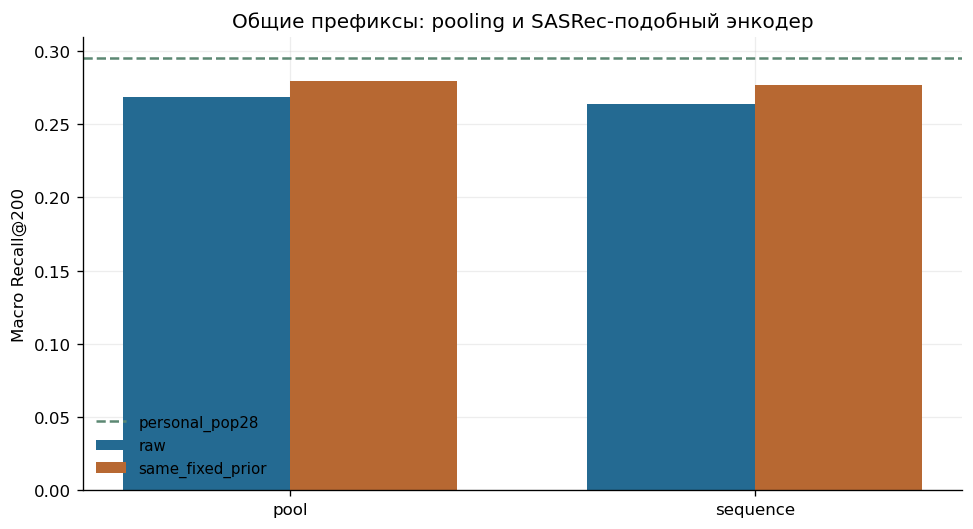

,encoder,method,recall_reachable@200,own_minus_shuffled,best_updates
0,pool,pool_raw,0.268336,0.019259,2000
1,pool,pool_same_fixed_prior,0.279342,0.015592,2000
2,sequence,sequence_raw,0.263624,0.000260,2000
3,sequence,sequence_same_fixed_prior,0.276956,0.000720,2000


In [6]:
encoders = read('prefix_sequence_20261104__comparison.csv')
fig, ax = plt.subplots(figsize=(8,4.3))
for offset,(scoring,color) in zip([-.18,.18],[('raw','#246A92'),('same_fixed_prior','#B76832')]):
    d=encoders[encoders.method.str.endswith(scoring)].sort_values('encoder')
    ax.bar(np.arange(len(d))+offset,d['recall_reachable@200'],.36,label=scoring,color=color)
ax.axhline(.2950456062720093,color='#5C8873',ls='--',label='personal_pop28')
ax.set(xticks=[0,1],xticklabels=['pool','sequence'],ylabel='Macro Recall@200',title='Общие префиксы: pooling и SASRec-подобный энкодер')
ax.legend(frameon=False,fontsize=9)
save_figure(fig, figures / 'encoders.png')
plt.show()
display(encoders[['encoder','method','recall_reachable@200','own_minus_shuffled','best_updates']])

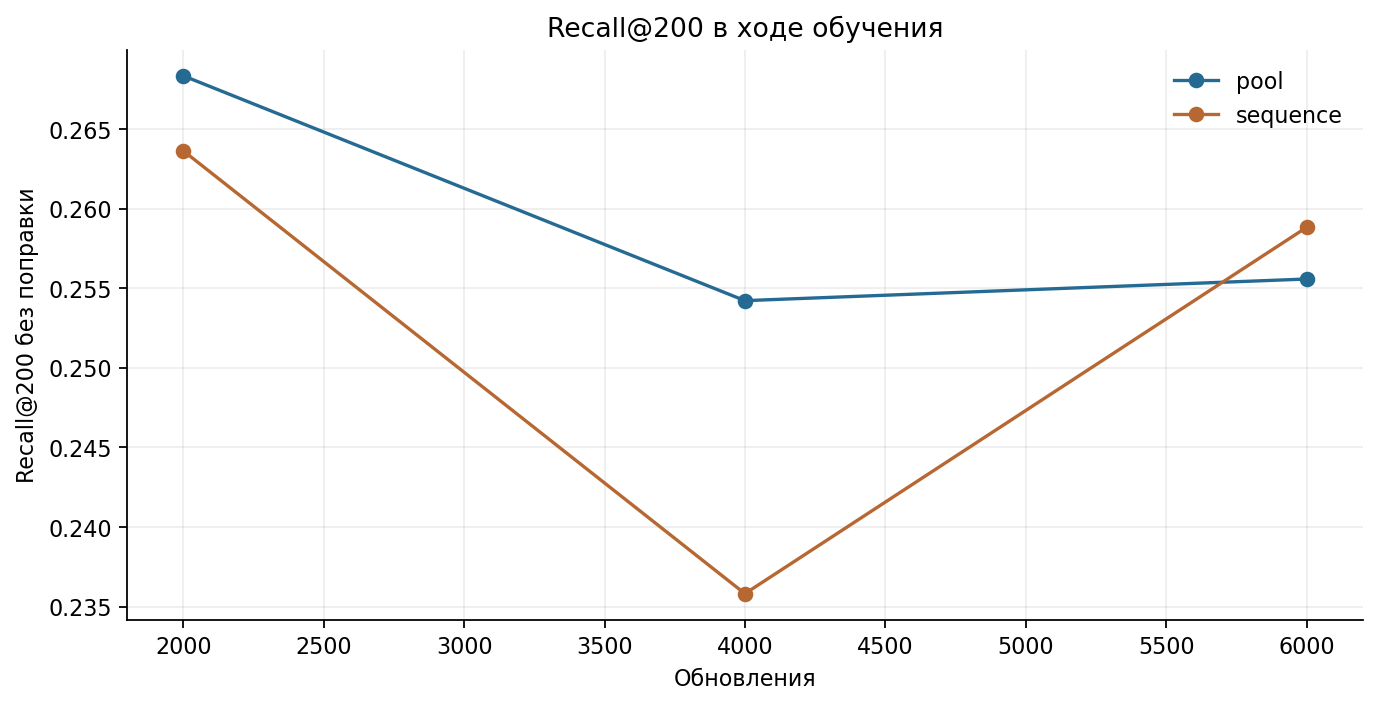

In [7]:
fig, ax = plt.subplots(figsize=(8.5,4.3))
for encoder,color in [('pool','#246A92'),('sequence','#B76832')]:
    curve=read(f'prefix_sequence_20261104__{encoder}__learning_curve.csv')
    ax.plot(curve.updates,curve.recall,'o-',label=encoder,color=color)
ax.set(xlabel='Обновления',ylabel='Recall@200 без поправки',title='Recall@200 в ходе обучения')
ax.legend(frameon=False)
save_figure(fig, figures / 'sequence_curves.png')
plt.show()

## Перестановка порядка

При фиксированных весах переставляем токены истории и измеряем разность Recall.

In [8]:
order = pd.DataFrame(read('prefix_sequence_20261104__sequence_order_diagnostic.json'))
display(order)

,mode,own_recall,shuffled_token_recall,own_minus_shuffled,ci95,permutation_seeds,caveat,weights_changed,final_test_used
0,raw,0.263624,0.263932,-0.000309,"[-0.0009914648058681154, 0.0002930207015430202]",1,Input corruption diagnostic; not proof that or...,False,False
1,same_fixed_prior,0.276956,0.277190,-0.000234,"[-0.0011048009032206762, 0.0006603282884113604]",1,Input corruption diagnostic; not proof that or...,False,False


## Горизонты 1, 3 и 7 дней

Для каждого горизонта сначала оцениваем пользователей с целями в этом интервале. Строки `first_day_matched` отдельно сравнивают горизонты на одинаковом наборе пользователей первого дня.

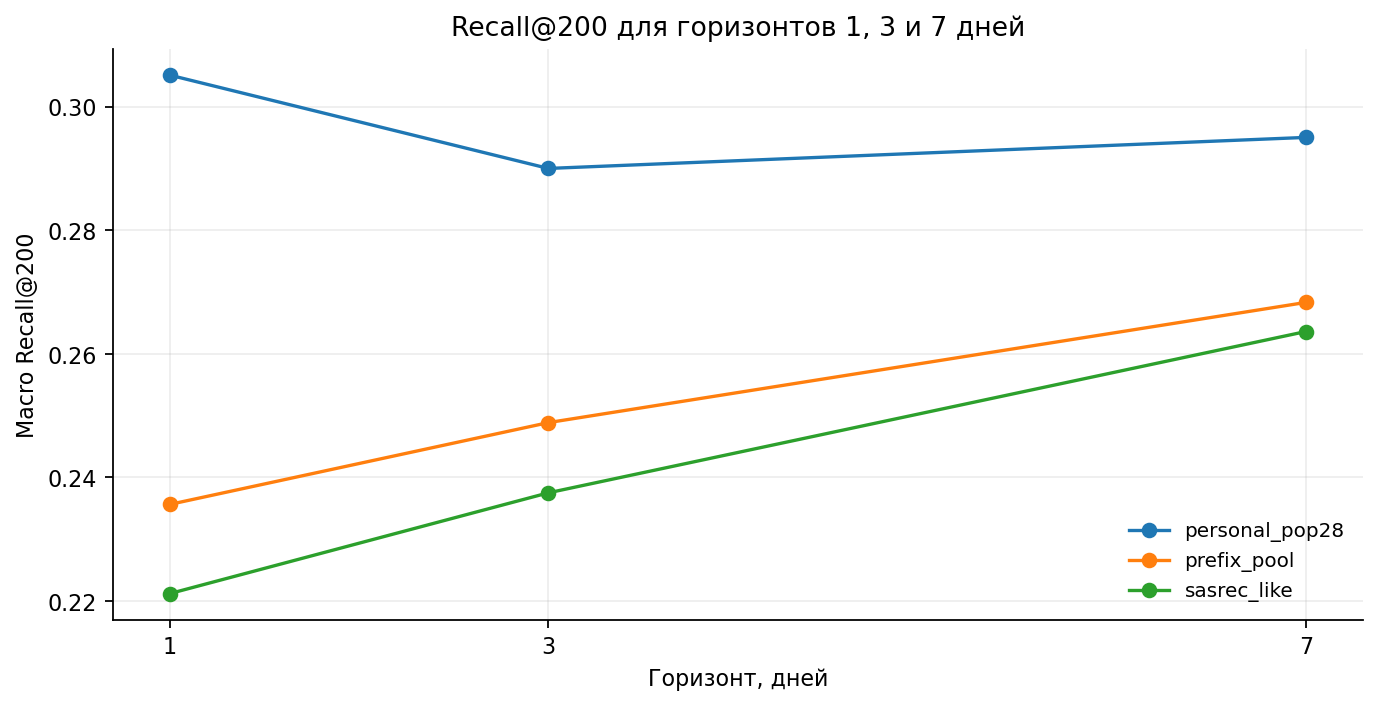

,method,days,users,recall_reachable@200
3,personal_pop28,1,796,0.305132
4,prefix_pool,1,796,0.235636
5,sasrec_like,1,796,0.221201
9,personal_pop28,3,796,0.299134
10,prefix_pool,3,796,0.233438
11,sasrec_like,3,796,0.218295
15,personal_pop28,7,796,0.288653
16,prefix_pool,7,796,0.227803
17,sasrec_like,7,796,0.215844


In [9]:
horizons = read('closing_checks_20261107__horizon_comparison.csv')
fig, ax = plt.subplots(figsize=(8.5,4.3))
for method,d in horizons[horizons.cohort == 'horizon'].groupby('method'):
    d=d.sort_values('days')
    ax.plot(d.days,d['recall_reachable@200'],'o-',label=method)
ax.set(xticks=[1,3,7],xlabel='Горизонт, дней',ylabel='Macro Recall@200',title='Recall@200 для горизонтов 1, 3 и 7 дней')
ax.legend(frameon=False,fontsize=9)
save_figure(fig, figures / 'horizons.png')
plt.show()
display(horizons[horizons.cohort == 'first_day_matched'][['method','days','users','recall_reachable@200']])

## Вывод

В исходном сравнении последовательный энкодер уступил усреднению истории и personal_pop28. Перестановка токенов не дала заметного снижения Recall. Новый запуск с блочным расчётом градиентов представлен отдельно в главе 07.